# Classical Text Classification for AI vs Human Writing Detection

This notebook develops a text classification pipeline to distinguish AI-generated and human-written academic abstracts using classical NLP feature extraction methods and machine learning models.

The analysis compares multiple combinations of feature extraction methods and classifiers, and then uses the selected model to estimate the proportion of AI-generated documents in two unseen text corpora.

## Objectives
- Build a text classification system for AI-generated vs human-written abstracts
- Compare CountVectorizer and TF-IDF representations
- Evaluate multiple classifiers, including Naive Bayes, kNN, Decision Tree, Logistic Regression, and SGDClassifier
- Select the best-performing model using a validation-based evaluation framework
- Estimate the proportion of AI-generated documents in two unseen datasets

## Dataset
The dataset consists of labeled academic abstracts for binary text classification, together with two unlabeled test corpora used for corpus-level estimation.

> Note: The dataset was provided as part of coursework and is included here for project demonstration purposes only.

# 0. Settings
Import packages

In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier

# 1. Load the training data
Load the training data into `train_df`. About 62% of the records are labeled as AI-generated, while 38% are labeled as human-generated.

In [ ]:
train_df = pd.read_csv('../data/raw/ai_hum_text.csv')
display(train_df.head())
display(train_df.shape)

,Text,Class
0,researchers have shown that using underwater i...,AI
1,this improvement signifies a more efficient al...,AI
2,however their performance can significantly de...,AI
3,this approach facilitates the documentation of...,AI
4,while rule based strategies demonstrate profic...,AI


(100561, 2)

In [3]:
display(train_df['Class'].value_counts())
display(train_df['Class'].value_counts(normalize=True))

Class
AI       62701
Human    37860
Name: count, dtype: int64

Class
AI       0.623512
Human    0.376488
Name: proportion, dtype: float64

# 2. Evaluate the performance
**(1) Feature extraction methods**

In scikit-learn, there are four main approaches to convert text documents into feature vectors: `CountVectorizer`, `HashingVectorizer`, `TfidfTransformer`, and `TfidfVectorizer`. Since `TfidfTransformer` must be applied after `CountVectorizer` and is equivalent to `TfidfVectorizer` and `HashingVectorizer` is better for large datasets, I will only focus on `CountVectorizer` and `TfidfVectorizer` here.

**(2) Classifier Models**

The models evaluated in this study include k-Nearest Neighbors (kNN), Naive Bayes, Decision Trees, and Logistic Regression.

Within the Naive Bayes family, `GaussianNB` and `CategoricalNB` are not suitable for this case: `GaussianNB` assumes features follow a Gaussian distribution, and `CategoricalNB` is designed for discrete categorical features. Therefore, only `MultinomialNB`, `ComplementNB`, and `BernoulliNB` are included in the comparison.

**(3) Evaluation Methodology**

Since the goal is to develop a text classification system that can identify AI-generated text and then estimate its proportion in a corpus, the key performance metrics can be grouped into two levels:

**Overall performance metrics:**

1.	Accuracy: the overall proportion of correctly classified documents.
2.	ROC-AUC: the ability of the classifier to discriminate between AI-generated and human-written text across different thresholds.

**Class-specific critical metrics (AI as positive label)**

3. F1-score: the harmonic mean of precision and recall, providing a balanced view of both.
4. Precision: Measures how reliable the model’s AI predictions are.
    - High: Most of the texts predicted as AI-generated are truly AI-generated.
    - Low: The model often misclassifies human-written content as AI-generated. It can have serious implications in academic contexts, as it could wrongly accuse authors of using AI tools.
5. Recall: Measures how completely the model captures AI-generated content.
    - High: The model successfully detects most AI-generated content.
    - Low: The model fails to recognize many AI texts and incorrectly classifies them as human-written. Without sufficient recall, the tool cannot effectively identify AI content and may be less useful for academic integrity checks or market adoption.

In addition, F1-score, precision, and recall with human as the positive label will also be included to facilitate comparison when model performances are close. However, the primary evaluation still relies on the five main metrics described above. Furthermore, the classification report and confusion matrix for each model combination are saved for detailed inspection when necessary.

A stratified sampling approach was applied to ensure that both the training, validation, and testing datasets preserve the same class distribution.
A three-way hold-out strategy was used, where the dataset was split into 50% training, 20% validation, and 30% testing sets.

In [4]:
X = train_df['Text']
y = train_df['Class']
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=2/7, random_state=42, stratify=y_temp)

In [5]:
# 22912 features are extracted
count_vect = CountVectorizer()
X_train_counts = count_vect.fit_transform(X_train)
display(count_vect.get_feature_names_out())
print(X_train_counts.shape)

array(['000x', '07x', '089mm', ..., 'zynq', 'µm', 'λi'],
      shape=(22912,), dtype=object)

(50280, 22912)


In [6]:
tfidf_vect = TfidfVectorizer()
X_train_tfidf = tfidf_vect.fit_transform(X_train)

# Compare CountVectorizer and TfidfVectorizer on the first document
count_values = X_train_counts[0].toarray()[0]
tfidf_values = X_train_tfidf[0].toarray()[0]

df_compare = pd.DataFrame({
    'word': count_vect.get_feature_names_out(),
    'count': count_values,
    'tfidf': tfidf_values
})

# Keep only words present in the document and sort by TF-IDF score
df_compare = df_compare[df_compare['count'] > 0].sort_values(by='tfidf', ascending=False)

# TF-IDF assigns different weights to words, even when the raw frequency is the same in CountVectorizer
display(df_compare.head(10))

,word,count,tfidf
13247,multiception,1,0.387737
19789,successful,1,0.248110
3672,combination,1,0.246607
9410,highlights,1,0.241286
14690,parameter,1,0.240494
10041,improved,1,0.224175
4332,convolutional,1,0.223769
22180,vision,1,0.217717
20769,tool,1,0.214030
3896,computer,1,0.211390


In [7]:
# results_df: Stores the evaluation metrics for all combinations
# clf_reports: Stores the classification reports for all combinations, with keys in the format "extractor_classifier_note"
# cf_matrices: Stores the confusion matrices for all combinations, with keys in the format "extractor_classifier_note"
# models: Stores the pipelines for all combinations, with keys in the format "extractor_classifier_note"
results_df = pd.DataFrame()
clf_reports = {}
cf_matrices = {}
models = {}

In [8]:
def eval_pipeline(classifier, results_df, note='', X_test=X_val, y_test=y_val):
    """
    Evaluate a given classifier with CountVectorizer and TfidfVectorizer.
    """
    extractors = [CountVectorizer(), TfidfVectorizer()]
    for extractor in extractors:
        # Build pipeline and train
        model = make_pipeline(extractor, classifier)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        ai_index = list(model.classes_).index('AI')
        
        # Compute metrics
        acc = round(accuracy_score(y_test, y_pred), 4)
        if hasattr(model, "predict_proba"):
            y_proba = model.predict_proba(X_test)[:, ai_index]
            y_test_01 = np.array([1 if y == 'AI' else 0 for y in y_test])
            auc = round(roc_auc_score(y_test_01, y_proba), 4)
        else:
            auc = np.nan
        ai_f1 = round(f1_score(y_test, y_pred, pos_label='AI', zero_division=0), 4)
        ai_prec = round(precision_score(y_test, y_pred, pos_label='AI', zero_division=0), 4)
        ai_rec = round(recall_score(y_test, y_pred, pos_label='AI', zero_division=0), 4)
        
        human_f1 = round(f1_score(y_test, y_pred, pos_label='Human', zero_division=0), 4)
        human_prec = round(precision_score(y_test, y_pred, pos_label='Human', zero_division=0), 4)
        human_rec = round(recall_score(y_test, y_pred, pos_label='Human', zero_division=0), 4)
    
        # Concat combination_result to results_df
        model_name = classifier.__class__.__name__
        extractor_name = extractor.__class__.__name__
        combination_result = pd.DataFrame([{
            'extraction_method': extractor_name,
            'model': model_name,
            'note': note,
            'accuracy': acc,
            'auc': auc,
            'ai_f1': ai_f1,
            'ai_precision': ai_prec,
            'ai_recall': ai_rec,
            'human_f1': human_f1,
            'human_precision': human_prec,
            'human_recall': human_rec
        }])
        results_df = pd.concat([results_df, combination_result], axis=0).reset_index(drop=True)
        results_df = results_df.drop_duplicates()

        model_identifier = f'{extractor_name}_{model_name}_{note}'
        clf_reports[model_identifier] = classification_report(y_test, y_pred)
        cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
        cf_matrices[model_identifier] = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
        models[model_identifier] = model
    return results_df

In [9]:
def show_styled_df(results_df):
    """
    Style the dataframe for better display
    """
    score_cols = ['accuracy', 'auc', 'ai_f1', 'ai_precision', 'ai_recall', 'human_f1', 'human_precision', 'human_recall']
    styled_df = results_df.style.background_gradient(cmap="YlOrRd").format("{:.2%}", subset=score_cols)
    display(styled_df)

## 2.1 Naive Bayes

### 2.1.1 `fit_prior=True`
Since the original dataset is imbalanced with 62% AI-labeled and 38% human-labeled samples, all three Naive Bayes models were first tested with `fit_prior=True` to preserve class proportions. Because `BernoulliNB` only considers the presence or absence of words and ignores their frequency, the results remain identical when using either `CountVectorizer` or `TfidfVectorizer`. To avoid duplicate entries, only the **BernoulliNB + CountVectorizer** combination will be retained for performance comparison.

Among the five tested combinations, **TfidfVectorizer + MultinomialNB** achieved the highest recall (96.82%) but the lowest precision (83.23%), indicating a strong tendency to classify most samples as AI. This behavior could lead to false accusations of AI usage in academic contexts, making it unsuitable despite its excellent recall.

In contrast, **BernoulliNB + CountVectorizer** produced solid and well-balanced results across all metrics. It achieved the highest overall performance (accuracy, AUC, F1), and while its precision and recall are slightly lower than other combinations, the differences are within 1%. Therefore, this combination is considered the most reliable and will be used for further comparison with other models.

In [10]:
results_df = eval_pipeline(classifier=MultinomialNB(fit_prior=True), 
                           note='fit_prior=True',
                           results_df=results_df)
results_df = eval_pipeline(classifier=ComplementNB(fit_prior=True),
                           note='fit_prior=True',
                           results_df=results_df)
results_df = eval_pipeline(classifier=BernoulliNB(fit_prior=True),
                           note='fit_prior=True',
                           results_df=results_df)
display(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,MultinomialNB,fit_prior=True,0.8901,0.9577,0.9119,0.9114,0.9125,0.8539,0.8548,0.8530
1,TfidfVectorizer,MultinomialNB,fit_prior=True,0.8585,0.9543,0.8951,0.8323,0.9682,0.7827,0.9278,0.6768
2,CountVectorizer,ComplementNB,fit_prior=True,0.8899,0.9577,0.9103,0.9248,0.8963,0.8574,0.8366,0.8793
3,TfidfVectorizer,ComplementNB,fit_prior=True,0.8878,0.9543,0.9104,0.9062,0.9147,0.8498,0.8565,0.8432
4,CountVectorizer,BernoulliNB,fit_prior=True,0.8966,0.9608,0.9165,0.9235,0.9096,0.8644,0.8539,0.8752
5,TfidfVectorizer,BernoulliNB,fit_prior=True,0.8966,0.9608,0.9165,0.9235,0.9096,0.8644,0.8539,0.8752


In [11]:
# Drop the BernoulliNB + TfidfVectorizer to remove duplicate
results_df = results_df.drop(results_df[results_df.index== 5].index)
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,MultinomialNB,fit_prior=True,89.01%,95.77%,91.19%,91.14%,91.25%,85.39%,85.48%,85.30%
1,TfidfVectorizer,MultinomialNB,fit_prior=True,85.85%,95.43%,89.51%,83.23%,96.82%,78.27%,92.78%,67.68%
2,CountVectorizer,ComplementNB,fit_prior=True,88.99%,95.77%,91.03%,92.48%,89.63%,85.74%,83.66%,87.93%
3,TfidfVectorizer,ComplementNB,fit_prior=True,88.78%,95.43%,91.04%,90.62%,91.47%,84.98%,85.65%,84.32%
4,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%


In [12]:
# Keep the best one
results_df = results_df[(results_df['model'] == 'BernoulliNB')]

### 2.1.2 `fit_prior=False`
Although `fit_prior` is generally recommended to be set as `True` when the dataset is imbalanced, the case with `fit_prior=False` is also tested here to verify whether the performance aligns with the assumptions.

From the results, among the six combinations, **BernoulliNB + fit_prior=True** still achieves the best overall performance in terms of accuracy, AUC, and F1-score. Although its precision and recall are not the highest, the differences are minor, making it the most balanced and reliable candidate so far.

Interestingly, **BernoulliNB + fit_prior=False** also performs quite well, achieving about 1% higher AI precision and 2% higher human recall compared to its `fit_prior=True` one. However, it performs worse on human precision and AI recall, indicating that it tends to classify more samples as “human.” This is consistent with the expected behavior, since setting `fit_prior=False` makes the model assume a more balanced class distribution.

Therefore, **BernoulliNB + fit_prior=True** remains the preferred model due to its high and well-balanced overall performance.

In [13]:
results_df = eval_pipeline(classifier=MultinomialNB(fit_prior=False),
                           note='fit_prior=False',
                           results_df=results_df)
results_df = eval_pipeline(classifier=ComplementNB(fit_prior=False),
                           note='fit_prior=False',
                           results_df=results_df)
results_df = eval_pipeline(classifier=BernoulliNB(fit_prior=False),
                           note='fit_prior=False',
                           results_df=results_df)
results_df = results_df.drop(results_df[(results_df['extraction_method'] == 'TfidfVectorizer') & (results_df['model'] == 'BernoulliNB')].index)

In [14]:
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%
1,CountVectorizer,MultinomialNB,fit_prior=False,88.99%,95.77%,91.03%,92.48%,89.63%,85.74%,83.66%,87.93%
2,TfidfVectorizer,MultinomialNB,fit_prior=False,88.78%,95.43%,91.04%,90.62%,91.47%,84.98%,85.65%,84.32%
3,CountVectorizer,ComplementNB,fit_prior=False,88.99%,95.77%,91.03%,92.48%,89.63%,85.74%,83.66%,87.93%
4,TfidfVectorizer,ComplementNB,fit_prior=False,88.78%,95.43%,91.04%,90.62%,91.47%,84.98%,85.65%,84.32%
5,CountVectorizer,BernoulliNB,fit_prior=False,89.41%,96.08%,91.31%,93.49%,89.23%,86.45%,83.42%,89.71%


In [15]:
# Keep the best one
results_df = results_df[(results_df['model'] == 'BernoulliNB') & (results_df['note'] == 'fit_prior=True')]

CountVectorizer_BernoulliNB_fit_prior=True


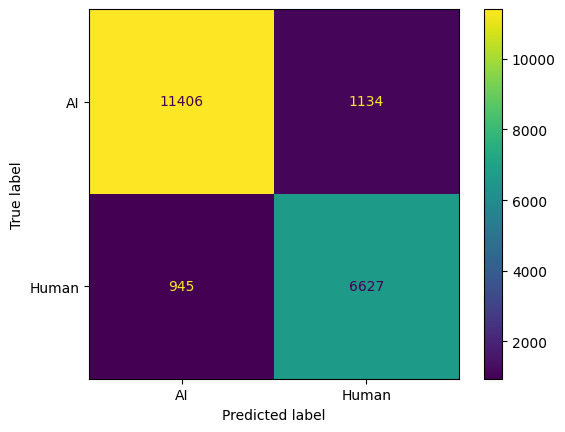

CountVectorizer_BernoulliNB_fit_prior=False


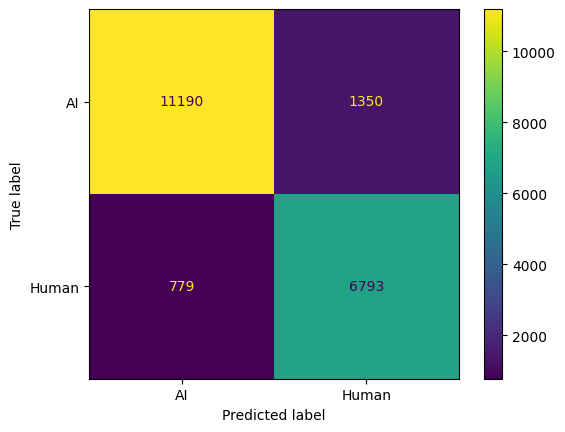

In [16]:
# Check the confusion matrices of both BernoulliNB model
comb = 'CountVectorizer_BernoulliNB_fit_prior=True'
print(comb)
cf_matrices[comb].plot()
plt.show()

# More "Human" is predicted in this model
comb = 'CountVectorizer_BernoulliNB_fit_prior=False'
print(comb)
cf_matrices[comb].plot()
plt.show()

## 2.2 k-Nearest Neighbour

kNN is evaluated using `n_neighbors = 3` here. Regardless of the feature extractor used, the overall results are significantly worse than those obtained with the Naive Bayes family of models. Notably, with the combination of **TfidfVectorizer + KNeighborsClassifier**, the human_recall score reached 81.27%, while ai_recall was only 5.39%. This indicates that the model almost always labels the samples as human-generated, showing that it does not perform well. In addition, predictions using `algorithm='brute'` take considerably longer than those of Naive Bayes, likely due to the extremely high dimensionality of the text features (22,912 features). Therefore, other algorithms will be tested with larger values of `n_neighbors` to further evaluate their performance.

In [19]:
t_start = time.time()
results_df = eval_pipeline(classifier=KNeighborsClassifier(n_neighbors=3, algorithm='brute', n_jobs=-1),
                           note='brute_3',
                           results_df=results_df)
t = time.time() - t_start
print('brute: {round(t, 2)} seconds')

brute: {round(t, 2)} seconds


In [20]:
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%
1,CountVectorizer,KNeighborsClassifier,brute_3,65.36%,67.13%,71.68%,73.11%,70.30%,55.41%,53.76%,57.17%
2,TfidfVectorizer,KNeighborsClassifier,brute_3,33.96%,43.70%,9.24%,32.28%,5.39%,48.10%,34.15%,81.27%


In [21]:
# Keep the best one
results_df = results_df[(results_df['model'] == 'BernoulliNB') & (results_df['note'] == 'fit_prior=True')]

### 2.2.1 `algorithm`
Although other algorithms were considered to improve efficiency, the data is represented as a sparse matrix, which causes scikit-learn to fall back to brute-force computation. As a result, both algorithms yield identical outcomes. Increasing the value of n_neighbors leads to changes in overall performance. However, it also amplifies the disparity between human_recall and ai_recall. Since no performance improvement was observed and computational acceleration was not achieved, the results suggest that k-NN may not be a suitable method for this task.

In [22]:
algs = ['ball_tree', 'kd_tree']
for alg in algs:
    t_start = time.time()
    results_df = eval_pipeline(classifier=KNeighborsClassifier(n_neighbors=30, algorithm=alg, n_jobs=-1),
                               note=f'{alg}_30',
                               results_df=results_df)
    t = time.time() - t_start
    print(f'{alg}: {round(t, 2)} seconds')

/opt/anaconda3/envs/COMP47750/lib/python3.13/site-packages/sklearn/neighbors/_base.py:598: UserWarning: cannot use tree with sparse input: using brute force
  warnings.warn("cannot use tree with sparse input: using brute force")
/opt/anaconda3/envs/COMP47750/lib/python3.13/site-packages/sklearn/neighbors/_base.py:598: UserWarning: cannot use tree with sparse input: using brute force
  warnings.warn("cannot use tree with sparse input: using brute force")


ball_tree: 133.02 seconds


/opt/anaconda3/envs/COMP47750/lib/python3.13/site-packages/sklearn/neighbors/_base.py:598: UserWarning: cannot use tree with sparse input: using brute force
  warnings.warn("cannot use tree with sparse input: using brute force")
/opt/anaconda3/envs/COMP47750/lib/python3.13/site-packages/sklearn/neighbors/_base.py:598: UserWarning: cannot use tree with sparse input: using brute force
  warnings.warn("cannot use tree with sparse input: using brute force")


kd_tree: 151.88 seconds


In [23]:
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%
1,CountVectorizer,KNeighborsClassifier,ball_tree_30,64.41%,74.47%,65.99%,81.64%,55.37%,62.68%,51.78%,79.37%
2,TfidfVectorizer,KNeighborsClassifier,ball_tree_30,37.75%,47.19%,0.35%,91.67%,0.18%,54.74%,37.68%,99.97%
3,CountVectorizer,KNeighborsClassifier,kd_tree_30,64.41%,74.47%,65.99%,81.64%,55.37%,62.68%,51.78%,79.37%
4,TfidfVectorizer,KNeighborsClassifier,kd_tree_30,37.75%,47.19%,0.35%,91.67%,0.18%,54.74%,37.68%,99.97%


CountVectorizer_KNeighborsClassifier_kd_tree_30


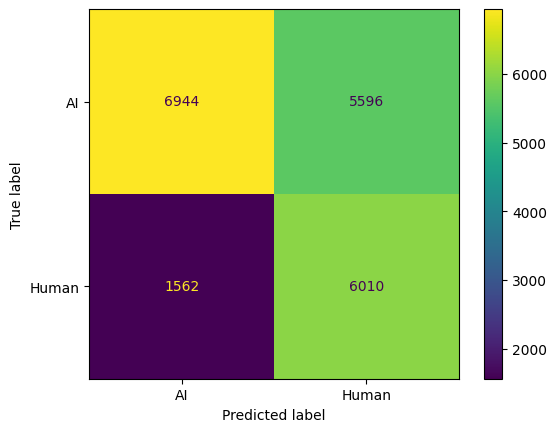

TfidfVectorizer_KNeighborsClassifier_kd_tree_30


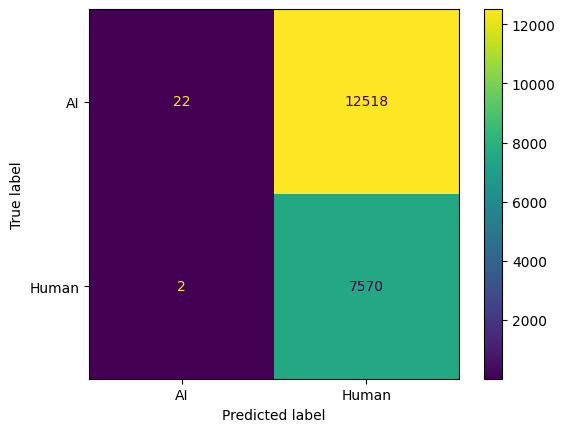

In [24]:
# Check the confusion matrix
comb = 'CountVectorizer_KNeighborsClassifier_kd_tree_30'
print(comb)
cf_matrices[comb].plot()
plt.show()

comb = 'TfidfVectorizer_KNeighborsClassifier_kd_tree_30'
print(comb)
cf_matrices[comb].plot()
plt.show()

In [25]:
# Keep the BernoulliNB one
results_df = results_df[(results_df['model'] == 'BernoulliNB') & (results_df['note'] == 'fit_prior=True')]
results_df

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,0.8966,0.9608,0.9165,0.9235,0.9096,0.8644,0.8539,0.8752


## 2.3 Decision Tree

### 2.3.1 `criterion`
The criteria “gini” and “entropy” were used to compare the performance of the Decision Tree Classifier. Although both performed worse than the BernoulliNB models, the “entropy” criterion consistently outperformed “gini” across both extraction methods. Therefore, entropy will be adopted as the criterion for further parameter tuning.

In [26]:
results_df = eval_pipeline(classifier=DecisionTreeClassifier(),
                           note="gini",
                           results_df=results_df)
results_df = eval_pipeline(classifier=DecisionTreeClassifier(criterion='entropy'),
                           note="entropy",
                           results_df=results_df)
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%
1,CountVectorizer,DecisionTreeClassifier,gini,81.26%,79.95%,85.05%,84.65%,85.45%,74.92%,75.52%,74.34%
2,TfidfVectorizer,DecisionTreeClassifier,gini,79.98%,78.67%,83.97%,83.87%,84.06%,73.37%,73.50%,73.23%
3,CountVectorizer,DecisionTreeClassifier,entropy,81.94%,80.91%,85.47%,85.74%,85.20%,76.13%,75.74%,76.53%
4,TfidfVectorizer,DecisionTreeClassifier,entropy,80.28%,79.08%,84.15%,84.33%,83.98%,73.90%,73.65%,74.15%


### 2.3.2 `min_impurity_decrease`
Since a bushy decision tree may lead to overfitting and poor generalization, pruning was applied to improve performance. The parameter `min_impurity_decrease` was tuned with values of 0.1, 0.01, and 0.001. However, the overall results still indicate that BernoulliNB remains the best-performing model.

Interestingly, when `min_impurity_decrease` was set to 0.1, the model’s AI recall and human precision increased significantly, even higher than those of BernoulliNB. However, its AI precision and human recall dropped sharply. This suggests that the model became overly aggressive in labeling content as AI-generated, even for human-written samples, leading to poor discrimination ability.

One possible explanation is that the key decision boundaries distinguishing AI and human content lie in nodes with lower impurity. When those splits are pruned (by setting a higher min_impurity_decrease), the model loses its finer distinctions, resulting in degraded performance.

In [27]:
results_df = eval_pipeline(classifier=DecisionTreeClassifier(criterion='entropy', min_impurity_decrease=0.1),
                           note="criterion='entropy', min_impurity_decrease=0.1",
                           results_df=results_df)
results_df = eval_pipeline(classifier=DecisionTreeClassifier(criterion='entropy', min_impurity_decrease=0.01),
                           note="criterion='entropy', min_impurity_decrease=0.01",
                           results_df=results_df)
results_df = eval_pipeline(classifier=DecisionTreeClassifier(criterion='entropy', min_impurity_decrease=0.001),
                           note="criterion='entropy', min_impurity_decrease=0.001",
                           results_df=results_df)
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%
1,CountVectorizer,DecisionTreeClassifier,gini,81.26%,79.95%,85.05%,84.65%,85.45%,74.92%,75.52%,74.34%
2,TfidfVectorizer,DecisionTreeClassifier,gini,79.98%,78.67%,83.97%,83.87%,84.06%,73.37%,73.50%,73.23%
3,CountVectorizer,DecisionTreeClassifier,entropy,81.94%,80.91%,85.47%,85.74%,85.20%,76.13%,75.74%,76.53%
4,TfidfVectorizer,DecisionTreeClassifier,entropy,80.28%,79.08%,84.15%,84.33%,83.98%,73.90%,73.65%,74.15%
5,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', min_impurity_decrease=0.1",73.62%,65.39%,82.36%,70.64%,98.73%,47.77%,93.85%,32.04%
6,TfidfVectorizer,DecisionTreeClassifier,"criterion='entropy', min_impurity_decrease=0.1",73.62%,65.39%,82.36%,70.64%,98.73%,47.77%,93.85%,32.04%
7,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', min_impurity_decrease=0.01",76.02%,77.08%,83.48%,73.19%,97.13%,56.33%,89.63%,41.07%
8,TfidfVectorizer,DecisionTreeClassifier,"criterion='entropy', min_impurity_decrease=0.01",75.93%,79.22%,83.42%,73.10%,97.15%,56.07%,89.61%,40.80%
9,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', min_impurity_decrease=0.001",78.91%,85.83%,83.28%,82.36%,84.21%,71.47%,72.84%,70.14%


CountVectorizer_DecisionTreeClassifier_criterion='entropy', min_impurity_decrease=0.1


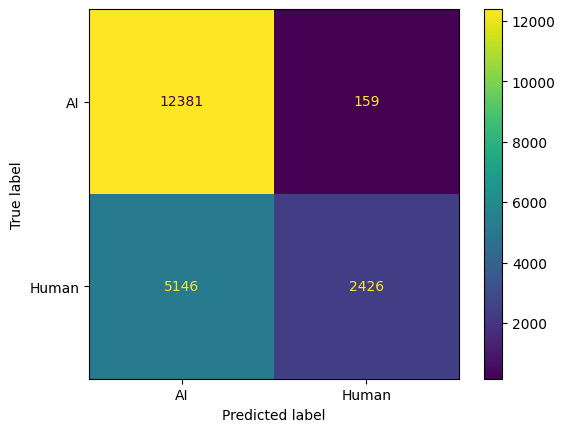

In [28]:
comb = "CountVectorizer_DecisionTreeClassifier_criterion='entropy', min_impurity_decrease=0.1"
print(comb)
cf_matrices[comb].plot()
plt.show()

In [29]:
# Remove models with min_impurity_decrease tuning
results_df = results_df[results_df.index < 5]

### 2.3.3 `min_samples_leaf`
After examining the current leaf sample counts of the model **CountVectorizer_DecisionTreeClassifier_entropy**, the values 2, 5, and 10 were selected for tuning based on the median, 75th percentile, and mean leaf sizes. The tuned models achieved higher AUC scores, indicating a stronger ability to distinguish AI-generated content from human-written content. However, BernoulliNB still remains the best-performing model overall across all evaluation metrics.

In [30]:
# View the current leaf counts
tree = models['CountVectorizer_DecisionTreeClassifier_entropy'].named_steps['decisiontreeclassifier']
is_leaf = tree.tree_.children_left == -1
leaf_counts = tree.tree_.n_node_samples[is_leaf]

print('Mean:', np.mean(leaf_counts))
print('25% quantile:', np.percentile(leaf_counts, 25))
print('50% quantile:', np.percentile(leaf_counts, 50))
print('75% quantile:', np.percentile(leaf_counts, 75))
print('Min:', np.min(leaf_counts))
print('Max:', np.max(leaf_counts))

Mean: 10.039936102236421
25% quantile: 1.0
50% quantile: 2.0
75% quantile: 5.0
Min: 1
Max: 1443


In [31]:
for i in [2, 5, 10]:
    results_df = eval_pipeline(classifier=DecisionTreeClassifier(criterion='entropy', min_samples_leaf=i),
                           note=f"criterion='entropy', min_samples_leaf={i}",
                           results_df=results_df)
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%
1,CountVectorizer,DecisionTreeClassifier,gini,81.26%,79.95%,85.05%,84.65%,85.45%,74.92%,75.52%,74.34%
2,TfidfVectorizer,DecisionTreeClassifier,gini,79.98%,78.67%,83.97%,83.87%,84.06%,73.37%,73.50%,73.23%
3,CountVectorizer,DecisionTreeClassifier,entropy,81.94%,80.91%,85.47%,85.74%,85.20%,76.13%,75.74%,76.53%
4,TfidfVectorizer,DecisionTreeClassifier,entropy,80.28%,79.08%,84.15%,84.33%,83.98%,73.90%,73.65%,74.15%
5,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=2",81.46%,82.62%,85.26%,84.56%,85.97%,75.04%,76.11%,74.00%
6,TfidfVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=2",79.51%,79.82%,83.67%,83.15%,84.20%,72.50%,73.28%,71.74%
7,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=5",81.54%,86.84%,85.38%,84.36%,86.43%,74.98%,76.57%,73.45%
8,TfidfVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=5",79.61%,83.92%,83.68%,83.55%,83.81%,72.85%,73.05%,72.66%
9,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=10",81.94%,88.81%,85.59%,85.15%,86.04%,75.81%,76.47%,75.16%


Since the previous results showed that increasing `min_samples_leaf` led to a noticeable improvement in AUC while other metrics remained relatively stable, further tuning was performed to observe the trend. The AUC reached its peak when `min_samples_leaf=20`, but started to decline as the value increased further. However, BernoulliNB still demonstrates the best performance among all models overall.

In [32]:
for i in [20, 30, 40]:
    results_df = eval_pipeline(classifier=DecisionTreeClassifier(criterion='entropy', min_samples_leaf=i),
                           note=f"criterion='entropy', min_samples_leaf={i}",
                           results_df=results_df)
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%
1,CountVectorizer,DecisionTreeClassifier,gini,81.26%,79.95%,85.05%,84.65%,85.45%,74.92%,75.52%,74.34%
2,TfidfVectorizer,DecisionTreeClassifier,gini,79.98%,78.67%,83.97%,83.87%,84.06%,73.37%,73.50%,73.23%
3,CountVectorizer,DecisionTreeClassifier,entropy,81.94%,80.91%,85.47%,85.74%,85.20%,76.13%,75.74%,76.53%
4,TfidfVectorizer,DecisionTreeClassifier,entropy,80.28%,79.08%,84.15%,84.33%,83.98%,73.90%,73.65%,74.15%
5,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=2",81.46%,82.62%,85.26%,84.56%,85.97%,75.04%,76.11%,74.00%
6,TfidfVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=2",79.51%,79.82%,83.67%,83.15%,84.20%,72.50%,73.28%,71.74%
7,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=5",81.54%,86.84%,85.38%,84.36%,86.43%,74.98%,76.57%,73.45%
8,TfidfVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=5",79.61%,83.92%,83.68%,83.55%,83.81%,72.85%,73.05%,72.66%
9,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', min_samples_leaf=10",81.94%,88.81%,85.59%,85.15%,86.04%,75.81%,76.47%,75.16%


In [33]:
# Keep the best one
results_df = results_df[(results_df['model'] == 'BernoulliNB') & (results_df['note'] == 'fit_prior=True')]

### 2.3.3 `max_depth`
The `max_depth` parameter was also applied to prune the decision tree. However, the performance difference after tuning was minimal, and the BernoulliNB model still achieved the best results.

In [34]:
tree = models['CountVectorizer_DecisionTreeClassifier_entropy'].named_steps['decisiontreeclassifier']
print(tree.get_depth())

361


In [35]:
for i in [100, 200, 300]:
    results_df = eval_pipeline(classifier=DecisionTreeClassifier(criterion='entropy', max_depth=i),
                           note=f"criterion='entropy', max_depth={i}",
                           results_df=results_df)
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%
1,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', max_depth=100",81.94%,82.33%,85.38%,86.17%,84.61%,76.36%,75.25%,77.51%
2,TfidfVectorizer,DecisionTreeClassifier,"criterion='entropy', max_depth=100",80.17%,80.05%,83.89%,85.00%,82.81%,74.21%,72.69%,75.79%
3,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', max_depth=200",82.12%,81.18%,85.61%,85.93%,85.29%,76.40%,75.93%,76.88%
4,TfidfVectorizer,DecisionTreeClassifier,"criterion='entropy', max_depth=200",80.13%,78.91%,84.03%,84.22%,83.84%,73.71%,73.43%,73.98%
5,CountVectorizer,DecisionTreeClassifier,"criterion='entropy', max_depth=300",81.91%,80.93%,85.44%,85.77%,85.10%,76.13%,75.65%,76.62%
6,TfidfVectorizer,DecisionTreeClassifier,"criterion='entropy', max_depth=300",80.22%,79.00%,84.12%,84.24%,84.00%,73.79%,73.62%,73.97%


In [36]:
# Keep the best one
results_df = results_df[(results_df['model'] == 'BernoulliNB') & (results_df['note'] == 'fit_prior=True')]

## 2.4 Logistic Regression

Surprisingly, Logistic Regression shows much better overall performance than BernoulliNB. Among the two feature extraction methods, CountVectorizer performs slightly better overall. Although it has slightly lower AI recall and human precision compared to TfidfVectorizer, the differences are minor, suggesting that it tends to classify more samples as human. Therefore, **CountVectorizer + LogisticRegression** can be considered the best-performing combination at this stage.

In [37]:
# max_iter is set to avoid iteration error 
results_df = eval_pipeline(classifier=LogisticRegression(max_iter=1000, random_state=42),
                           results_df=results_df)
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,BernoulliNB,fit_prior=True,89.66%,96.08%,91.65%,92.35%,90.96%,86.44%,85.39%,87.52%
1,CountVectorizer,LogisticRegression,,91.71%,97.40%,93.40%,92.74%,94.07%,88.86%,89.94%,87.81%
2,TfidfVectorizer,LogisticRegression,,91.31%,97.20%,93.14%,91.73%,94.60%,88.16%,90.57%,85.87%


CountVectorizer_LogisticRegression_


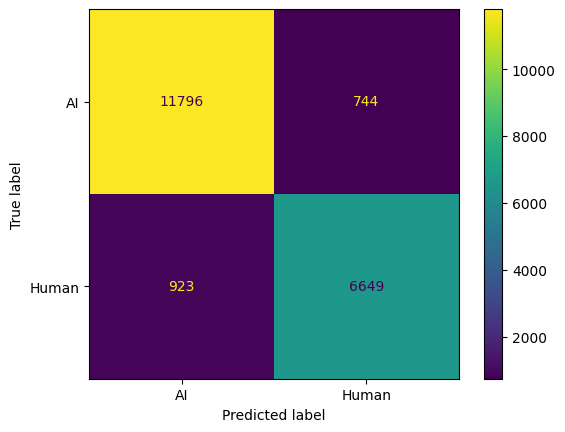

TfidfVectorizer_LogisticRegression_


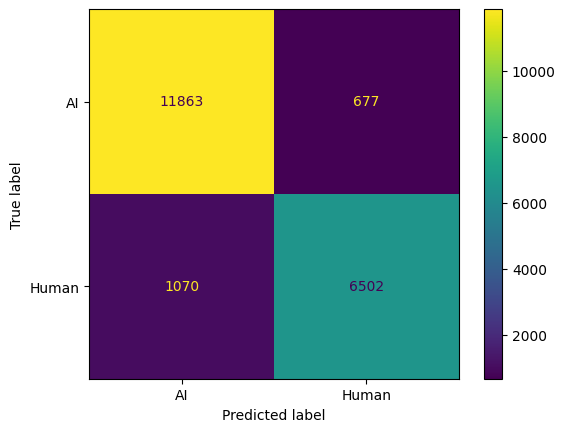

In [38]:
comb = "CountVectorizer_LogisticRegression_"
print(comb)
cf_matrices[comb].plot()
plt.show()

comb = "TfidfVectorizer_LogisticRegression_"
print(comb)
cf_matrices[comb].plot()
plt.show()

In [39]:
# Keep the best one
results_df = results_df[(results_df['extraction_method'] == 'CountVectorizer') & (results_df['model'] == 'LogisticRegression')]
results_df.head()

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
1,CountVectorizer,LogisticRegression,,0.9171,0.974,0.934,0.9274,0.9407,0.8886,0.8994,0.8781


### 2.4.1 `solver`
The default solver is lbfgs. Three common solvers are tested, but only minor performance differences are shown. Overall, the best configuration was `solver='saga'` with CountVectorizer, which delivered the most consistent results across metrics.

In [40]:
solvers = ['liblinear', 'sag', 'saga']
for solver in solvers:
    print(solver)
    results_df = eval_pipeline(classifier=LogisticRegression(max_iter=1000, random_state=42, solver=solver),
                               note=solver,
                               results_df=results_df)
show_styled_df(results_df)

liblinear
sag
saga


,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,,91.71%,97.40%,93.40%,92.74%,94.07%,88.86%,89.94%,87.81%
1,CountVectorizer,LogisticRegression,liblinear,91.73%,97.40%,93.41%,92.79%,94.04%,88.89%,89.91%,87.90%
2,TfidfVectorizer,LogisticRegression,liblinear,91.30%,97.18%,93.13%,91.71%,94.60%,88.14%,90.57%,85.84%
3,CountVectorizer,LogisticRegression,sag,91.74%,97.40%,93.42%,92.79%,94.06%,88.91%,89.93%,87.90%
4,TfidfVectorizer,LogisticRegression,sag,91.30%,97.18%,93.13%,91.71%,94.60%,88.13%,90.57%,85.83%
5,CountVectorizer,LogisticRegression,saga,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
6,TfidfVectorizer,LogisticRegression,saga,91.30%,97.18%,93.13%,91.71%,94.60%,88.13%,90.57%,85.83%


In [41]:
results_df = results_df[(results_df['extraction_method'] == 'CountVectorizer') & (results_df['note'] == 'saga')]

### 2.4.2 `class_weight`
Because the dataset is imbalanced, I also tested the “balanced” mode, which automatically adjusts class weights inversely proportional to the class frequencies in the input data. As expected, under CountVectorizer, the performances of the default setting (`class_weight=None`) and the balanced mode (`class_weight='balanced'`) are very similar. The difference lies mainly in their tendencies: the default setting achieves higher AI recall, meaning it is more inclined to predict samples as AI-generated, while the balanced mode achieves higher human recall, indicating a stronger ability to identify human-written texts. Both configurations perform well overall: `class_weight='balanced'` is preferable when minimizing false accusations against users is important, whereas `class_weight=None` is better suited when the goal is to capture as many AI-generated texts as possible.

In [42]:
results_df = eval_pipeline(classifier=LogisticRegression(max_iter=1000, random_state=42, solver='saga', class_weight='balanced'),
                           note="saga_balanced",
                           results_df=results_df)
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,saga,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
1,CountVectorizer,LogisticRegression,saga_balanced,91.69%,97.40%,93.27%,94.16%,92.40%,89.13%,87.79%,90.52%
2,TfidfVectorizer,LogisticRegression,saga_balanced,91.22%,97.19%,92.84%,94.37%,91.36%,88.64%,86.41%,90.98%


### 2.4.3 `C`
`C` represents the inverse of the regularization strength. Several values were tested (default = 1). However, it is found that values above 0.1 made little difference in performance. The only notable change occurred at `C = 0.01`, where the model showed extremely high AI recall and human precision, but a very low AI precision, indicating that the model tends to classify most samples as AI-generated.

Overall, adjusting C had only a minor impact on model optimization.

In [43]:
for c in [0.01, 0.1, 1, 10, 100]:
    results_df = eval_pipeline(classifier=LogisticRegression(max_iter=1000, random_state=42, solver='saga', C=c),
                               note=f"saga_{c}",
                               results_df=results_df)
    print(c)
show_styled_df(results_df)

0.01
0.1
1


/opt/anaconda3/envs/COMP47750/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


10


/opt/anaconda3/envs/COMP47750/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


100


,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,saga,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
1,CountVectorizer,LogisticRegression,saga_balanced,91.69%,97.40%,93.27%,94.16%,92.40%,89.13%,87.79%,90.52%
2,TfidfVectorizer,LogisticRegression,saga_balanced,91.22%,97.19%,92.84%,94.37%,91.36%,88.64%,86.41%,90.98%
3,CountVectorizer,LogisticRegression,saga_0.01,88.30%,95.60%,90.95%,87.82%,94.32%,83.45%,89.28%,78.33%
4,TfidfVectorizer,LogisticRegression,saga_0.01,71.93%,93.28%,81.58%,69.04%,99.70%,41.04%,98.10%,25.95%
5,CountVectorizer,LogisticRegression,saga_0.1,91.28%,97.17%,93.10%,91.93%,94.30%,88.17%,90.14%,86.29%
6,TfidfVectorizer,LogisticRegression,saga_0.1,87.50%,95.74%,90.53%,85.76%,95.88%,81.60%,91.51%,73.63%
7,CountVectorizer,LogisticRegression,saga_1,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
8,TfidfVectorizer,LogisticRegression,saga_1,91.30%,97.18%,93.13%,91.71%,94.60%,88.13%,90.57%,85.83%
9,CountVectorizer,LogisticRegression,saga_10,91.08%,96.92%,92.89%,92.34%,93.45%,88.04%,88.94%,87.16%


TfidfVectorizer_LogisticRegression_saga_0.01


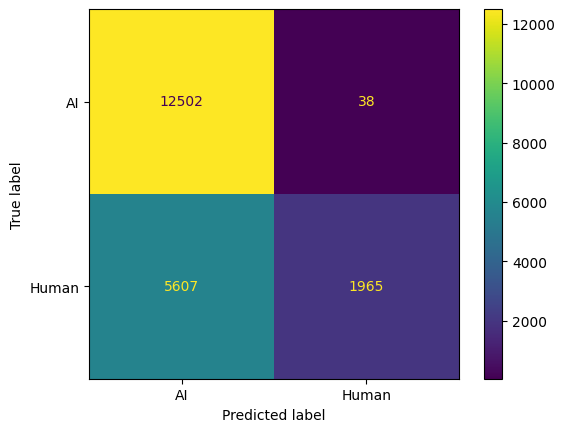

In [44]:
comb = "TfidfVectorizer_LogisticRegression_saga_0.01"
print(comb)
cf_matrices[comb].plot()
plt.show()

In [45]:
for c in [0.01, 0.1, 1, 10, 100]:
    results_df = eval_pipeline(classifier=LogisticRegression(max_iter=1000, random_state=42, solver='saga', class_weight='balanced', C=c),
                               note=f"saga_balanced_{c}",
                               results_df=results_df)
    print(c)
show_styled_df(results_df)

0.01
0.1
1


/opt/anaconda3/envs/COMP47750/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


10


/opt/anaconda3/envs/COMP47750/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


100


,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,saga,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
1,CountVectorizer,LogisticRegression,saga_balanced,91.69%,97.40%,93.27%,94.16%,92.40%,89.13%,87.79%,90.52%
2,TfidfVectorizer,LogisticRegression,saga_balanced,91.22%,97.19%,92.84%,94.37%,91.36%,88.64%,86.41%,90.98%
3,CountVectorizer,LogisticRegression,saga_0.01,88.30%,95.60%,90.95%,87.82%,94.32%,83.45%,89.28%,78.33%
4,TfidfVectorizer,LogisticRegression,saga_0.01,71.93%,93.28%,81.58%,69.04%,99.70%,41.04%,98.10%,25.95%
5,CountVectorizer,LogisticRegression,saga_0.1,91.28%,97.17%,93.10%,91.93%,94.30%,88.17%,90.14%,86.29%
6,TfidfVectorizer,LogisticRegression,saga_0.1,87.50%,95.74%,90.53%,85.76%,95.88%,81.60%,91.51%,73.63%
7,CountVectorizer,LogisticRegression,saga_1,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
8,TfidfVectorizer,LogisticRegression,saga_1,91.30%,97.18%,93.13%,91.71%,94.60%,88.13%,90.57%,85.83%
9,CountVectorizer,LogisticRegression,saga_10,91.08%,96.92%,92.89%,92.34%,93.45%,88.04%,88.94%,87.16%


Finally, since the main goal of this task is to distinguish between AI-generated and human-written text, the model with `class_weight=None` is selected, as it achieves slightly higher accuracy. However, this choice is based on the assumption that the model will not be directly used for detecting AI writing in contexts involving penalties or disciplinary actions. If such consequences are involved, a more conservative approach using `class_weight='balanced'` would be a better and fairer choice.

In [46]:
# Keep only the combinations of interest for easier comparison
results_df = results_df[(results_df['note'] == 'saga')]
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,saga,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%


## 2.5 SGDClassifier
SGDClassifier is tested here because the Support Vector Machine (SVM) is widely regarded as one of the best algorithms for text classification, as noted in [Working With Text Data](https://scikit-learn.org/1.4/tutorial/text_analytics/working_with_text_data.html). Although SVC is the true implementation of SVM, it is computationally expensive and slow on large datasets. Therefore, following the same approach described in the tutorial, SGDClassifier is used here as a faster, approximate alternative to SVM.

At first, the parameters from the [Working With Text Data](https://scikit-learn.org/1.4/tutorial/text_analytics/working_with_text_data.html) were used to evaluate the model’s performance. The results show that the performance of **CountVectorizer + SGDClassifier** is quite close to that of **CountVectorizer + LogisticRegression**, suggesting that this classifier is worth further tuning. As for the **TfidfVectorizer + SGDClassifier**, the ai_recall is excellent, but the precision score is poor. This may also lead to false accusations of AI usage in academic contexts, making it unsuitable for this task.

In [47]:
# Parameters are from the "Working With Text Data" page
results_df = eval_pipeline(classifier=SGDClassifier(loss='hinge', penalty='l2', alpha=1e-3, random_state=42, max_iter=5, tol=None),
                           results_df=results_df)

show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,saga,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
1,CountVectorizer,SGDClassifier,,90.84%,nan%,92.70%,92.12%,93.29%,87.70%,88.64%,86.78%
2,TfidfVectorizer,SGDClassifier,,81.53%,nan%,86.96%,77.68%,98.75%,68.36%,96.24%,53.01%


### 2.5.1 `loss`
First, `max_iter` is increased to 10 and different loss functions are compared: `hinge`, `log_loss`, and `modified_huber`. The results show that increasing `max_iter` helps improve performance, and the `modified_huber` loss function achieves the best results.

In [48]:
loss_functions = ['hinge', 'log_loss', 'modified_huber']
for loss_function in loss_functions:
    results_df = eval_pipeline(classifier=SGDClassifier(loss=loss_function, penalty='l2', alpha=1e-3, random_state=42, max_iter=10, tol=None),
                               note=f"{loss_function}_10",
                               results_df=results_df)
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,saga,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
1,CountVectorizer,SGDClassifier,,90.84%,nan%,92.70%,92.12%,93.29%,87.70%,88.64%,86.78%
2,TfidfVectorizer,SGDClassifier,,81.53%,nan%,86.96%,77.68%,98.75%,68.36%,96.24%,53.01%
3,CountVectorizer,SGDClassifier,hinge_10,91.01%,nan%,92.79%,92.76%,92.82%,88.05%,88.10%,88.01%
4,TfidfVectorizer,SGDClassifier,hinge_10,81.42%,nan%,86.89%,77.57%,98.76%,68.12%,96.24%,52.72%
5,CountVectorizer,SGDClassifier,log_loss_10,89.83%,96.30%,91.98%,90.46%,93.55%,86.10%,88.68%,83.66%
6,TfidfVectorizer,SGDClassifier,log_loss_10,79.03%,93.99%,85.47%,75.22%,98.96%,62.30%,96.38%,46.02%
7,CountVectorizer,SGDClassifier,modified_huber_10,91.75%,97.26%,93.33%,94.00%,92.68%,89.16%,88.15%,90.20%
8,TfidfVectorizer,SGDClassifier,modified_huber_10,89.56%,96.44%,91.93%,88.76%,95.33%,85.23%,91.19%,80.01%


In [49]:
# Keep only the combinations of interest for easier comparison
results_df = results_df[results_df['note'].isin(['saga', 'modified_huber_10']) & (results_df['extraction_method'] == 'CountVectorizer')]

### 2.5.2 `max_iter`
The `max_iter` parameter was gradually increased while using the `modified_huber` loss, with the expectation that performance would keep improving. However, the best AI F1-score was achieved at `max_iter = 20` with CountVectorizer, and the differences among other settings were minimal. Overall, LogisticRegression still showed slightly better and more stable performance with the best AUC.

In [50]:
for i in [20, 30, 40, 50]:
    print(i)
    results_df = eval_pipeline(classifier=SGDClassifier(loss='modified_huber', penalty='l2', alpha=1e-3, random_state=42, max_iter=i, tol=None),
                               note=f"modified_huber_{i}",
                               results_df=results_df)
show_styled_df(results_df)

20
30
40
50


,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,saga,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
1,CountVectorizer,SGDClassifier,modified_huber_10,91.75%,97.26%,93.33%,94.00%,92.68%,89.16%,88.15%,90.20%
2,CountVectorizer,SGDClassifier,modified_huber_20,91.68%,97.28%,93.38%,92.57%,94.21%,88.78%,90.12%,87.48%
3,TfidfVectorizer,SGDClassifier,modified_huber_20,89.53%,96.44%,91.91%,88.69%,95.37%,85.18%,91.25%,79.86%
4,CountVectorizer,SGDClassifier,modified_huber_30,91.65%,97.30%,93.35%,92.71%,94.00%,88.78%,89.83%,87.76%
5,TfidfVectorizer,SGDClassifier,modified_huber_30,89.50%,96.44%,91.89%,88.63%,95.39%,85.11%,91.26%,79.74%
6,CountVectorizer,SGDClassifier,modified_huber_40,91.64%,97.32%,93.31%,93.14%,93.47%,88.86%,89.12%,88.60%
7,TfidfVectorizer,SGDClassifier,modified_huber_40,89.52%,96.44%,91.90%,88.68%,95.37%,85.16%,91.25%,79.83%
8,CountVectorizer,SGDClassifier,modified_huber_50,91.60%,97.30%,93.31%,92.67%,93.96%,88.72%,89.77%,87.69%
9,TfidfVectorizer,SGDClassifier,modified_huber_50,89.52%,96.44%,91.90%,88.68%,95.37%,85.16%,91.25%,79.83%


In [51]:
# Keep only the combinations of interest for easier comparison
results_df = results_df[results_df['model'] == 'LogisticRegression']
results_df

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,saga,0.9175,0.974,0.9343,0.9278,0.9408,0.8891,0.8997,0.8788


## 2.6 Final model choice
After comparing the performance of several classifiers and different parameter combinations, the `LogisticRegression(max_iter=1000, random_state=42, solver='saga')` classifier with CountVectorizer was found to be the best combination.

Previously, model performance was evaluated using the validation set. The model was then confirmed on the test set. The difference across all evaluation metrics between the two sets was less than 1%, demonstrating strong generalization capability and consistent performance.

Final Test Results:
- Accuracy: 91.89%
- ROC-AUC: 97.57%
- Class-wise F1 / Precision / Recall:
    - AI: F1 93.53%, Precision 93.12%, Recall 93.93%
	- Human: F1 89.15%, Precision 89.81%, Recall 88.51%


In [52]:
results_df = eval_pipeline(classifier=LogisticRegression(max_iter=1000, random_state=42, solver='saga'),
                           X_test=X_test, 
                           y_test=y_test,
                           note="final_test_result",
                           results_df=results_df)
results_df = results_df[results_df['extraction_method'] == 'CountVectorizer']
show_styled_df(results_df)

,extraction_method,model,note,accuracy,auc,ai_f1,ai_precision,ai_recall,human_f1,human_precision,human_recall
0,CountVectorizer,LogisticRegression,saga,91.75%,97.40%,93.43%,92.78%,94.08%,88.91%,89.97%,87.88%
1,CountVectorizer,LogisticRegression,final_test_result,91.89%,97.57%,93.53%,93.12%,93.93%,89.15%,89.81%,88.51%


# 3. Classify new data
According to the selected model, the predicted results are as follows:

Test A (`test_Abst_A.csv`):\
predicted_label\
Human    0.729\
**AI       0.271** 🌟\
Name: proportion, dtype: float64\

Test B (`test_Abst_B.csv`):\
predicted_label\
Human    0.938\
AI       0.062\
Name: proportion, dtype: float64\

From these results, it can be observed that compared to Test B, where only 6.2% of the content is predicted to be AI-generated, Test A has a significantly higher proportion (27.1%) classified as AI-generated content. These estimates therefore suggest that the proportion of AI-generated text is higher in Test A.

However, these results are derived from a model with an overall accuracy of 91.89%, AI precision of 93.12%, AI recall of 93.93%, and an AI F1-score of 93.53%. Although the model demonstrates strong performance, it is not perfect. Therefore, we can reasonably infer a relative difference between the two datasets and conclude that Test A is likely to contain a higher proportion of AI-generated text, but these percentages should not be interpreted as exact representations of the true proportions of AI-generated content.

In [ ]:
test_a = pd.read_csv('../data/raw/test_Abst_A.csv')
test_b = pd.read_csv('../data/raw/test_Abst_B.csv')
display(test_a.head())
display(test_b.head())
display(test_a.shape)
display(test_b.shape)

,clean_abstract
0,in the era of burgeoning electric vehicle ev p...
1,in this study we apply two classification algo...
2,human–robot interaction hri systems are crucia...
3,pvpq switching of generator buses when hitting...
4,the internet of things is shaping the next gen...


,clean_abstract
0,style transfer aims to synthesize an image whi...
1,this paper formulates a chanceconstrained opti...
2,this paper introduces a design scheme of intel...
3,background artificial intelligence ai has beco...
4,based on the group heuristic model and the mod...


(1000, 1)

(1000, 1)

In [54]:
model = make_pipeline(CountVectorizer(), 
                      LogisticRegression(max_iter=1000, random_state=42, solver='saga'))
model.fit(X_train, y_train)
a_pred = model.predict(test_a['clean_abstract'])
b_pred = model.predict(test_b['clean_abstract'])

In [55]:
a_result = pd.concat([test_a, pd.DataFrame(a_pred, columns=['predicted_label'])], axis=1)
b_result = pd.concat([test_b, pd.DataFrame(b_pred, columns=['predicted_label'])], axis=1)
display(a_result.head())
display(b_result.head())

,clean_abstract,predicted_label
0,in the era of burgeoning electric vehicle ev p...,AI
1,in this study we apply two classification algo...,Human
2,human–robot interaction hri systems are crucia...,Human
3,pvpq switching of generator buses when hitting...,Human
4,the internet of things is shaping the next gen...,Human


,clean_abstract,predicted_label
0,style transfer aims to synthesize an image whi...,Human
1,this paper formulates a chanceconstrained opti...,Human
2,this paper introduces a design scheme of intel...,Human
3,background artificial intelligence ai has beco...,Human
4,based on the group heuristic model and the mod...,Human


In [56]:
print("Test A:")
display(a_result['predicted_label'].value_counts(normalize=True))

print("Test B:")
display(b_result['predicted_label'].value_counts(normalize=True))

Test A:


predicted_label
Human    0.729
AI       0.271
Name: proportion, dtype: float64

Test B:


predicted_label
Human    0.938
AI       0.062
Name: proportion, dtype: float64

Here, the previously considered model with `class_weight='balanced'` was also applied. The estimated proportions differed slightly, but it remained evident that Test A contained a higher percentage of AI-generated texts (27.2%) and a lower percentage of human-generated texts (72.8%) than Test B.

In [57]:
# Use the balanced model we found well before
model = make_pipeline(CountVectorizer(), 
                      LogisticRegression(max_iter=1000, random_state=42, solver='saga', class_weight='balanced'))

model.fit(X_train, y_train)
a_pred = model.predict(test_a['clean_abstract'])
b_pred = model.predict(test_b['clean_abstract'])
a_result = pd.concat([test_a, pd.DataFrame(a_pred, columns=['predicted_label'])], axis=1)
b_result = pd.concat([test_b, pd.DataFrame(b_pred, columns=['predicted_label'])], axis=1)
print("Test A:")
display(a_result['predicted_label'].value_counts(normalize=True))

print("Test B:")
display(b_result['predicted_label'].value_counts(normalize=True))

Test A:


predicted_label
Human    0.728
AI       0.272
Name: proportion, dtype: float64

Test B:


predicted_label
Human    0.941
AI       0.059
Name: proportion, dtype: float64